# Energy Calculation

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from qss import energy
from qss.distributions import prepare_2D_lattice_data, DistType
from tools.scientific_plot_v2 import ScientificPlotter, PlotConfig

plotter = ScientificPlotter()

## 2D Lattice

In [3]:
N = 100
t = -1
t_prim = 0.25
# t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

## Energy

In [4]:
mu = Path("chemical_potential_results.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    beta = 1/k_BT
    H_a = np.unique(mu_df["H_a"])

    if not "entropy"  in mu_df.columns:
        raise ValueError("Lack of the calculated chemical potential! Please run notebook number 2")
    
    if "energy" in mu_df.columns:
        energy_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
    else:
        mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
        energy_df = energy(mu_df, e_k)
        energy_df.to_csv("chemical_potential_results.csv")

else:
    raise("Lack of the calculated chemical potential! Please run notebook number 2")
energy_df

mu  iterations  converged      residual  \
distro n        k_BT   H_a                                                    
FD     0.010000 100.00 0.0 -529.350200          20       True  8.137874e-09   
       0.035359 100.00 0.0 -401.770506          23       True  1.583139e-08   
       0.060718 100.00 0.0 -346.402267          23       True  6.254147e-08   
       0.086077 100.00 0.0 -310.185179          22       True  1.685919e-09   
       0.111436 100.00 0.0 -283.029968          23       True  6.264613e-08   
...                                ...         ...        ...           ...   
SSL    0.897564 0.01   0.0    2.810296          17       True  5.297233e-08   
       0.922923 0.01   0.0    3.077111          23       True  2.783862e-08   
       0.948282 0.01   0.0    3.366265          23       True  8.989371e-08   
       0.973641 0.01   0.0    3.668974          23       True  4.617714e-08   
       0.999000 0.01   0.0    3.983881          25       True  5.561068e-08   

                             entropy    energy  free_energy  
distro n        k_BT   H_a                                   
FD     0.010000 100.00 0.0  0.062956 -0.000227    -6.295866  
       0.035359 100.00 0.0  0.177724 -0.000792   -17.773199  
       0.060718 100.00 0.0  0.271964 -0.001343   -27.197783  
       0.086077 100.00 0.0  0.354951 -0.001879   -35.496962  
       0.111436 100.00 0.0  0.430018 -0.002401   -43.004232  
...                              ...       ...          ...  
SSL    0.897564 0.01   0.0  0.624871 -0.057444    -0.063693  
       0.922923 0.01   0.0  0.643114 -0.000301    -0.006732  
       0.948282 0.01   0.0  0.660580 -0.000300    -0.006906  
       0.973641 0.01   0.0  0.677773 -0.000300    -0.007078  
       0.999000 0.01   0.0  0.694247 -0.000300    -0.007242  

[1000 rows x 7 columns]

# Energy

#### $\frac{S} {k_B N} = f(n)$

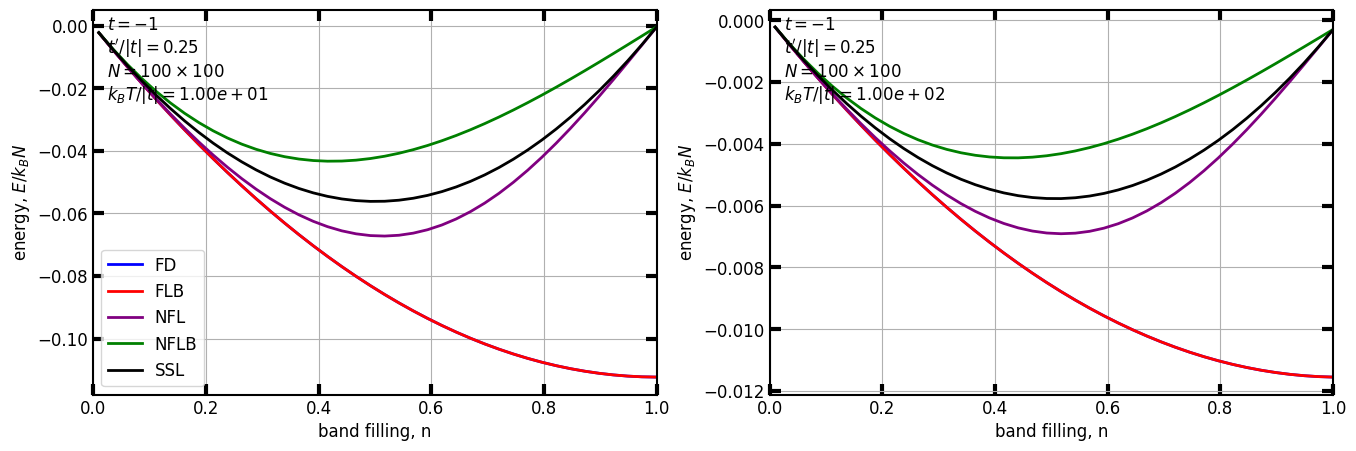

In [6]:
H_a_plot = H_a[0] 
beta_plot = 1/k_BT[-2:]

plotter.plot_scalar_result(
    results=energy_df,
    x_param="n",
    y_col="energy",
    y_label=r"energy, $E / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="beta",
    subplots_vals=beta_plot,
    cols=2,
    figsize=(8, 5),
    t_prim=t_prim,
    N=N,
    xlims=(0, 1)
)
plt.show()

## Free energy

$$ \frac{F}{N |t|} =  \frac{1}{N |t|}  \sum_k \epsilon_k n_k - \frac{k_bT}{|t|} \frac{S}{k_bN}$$


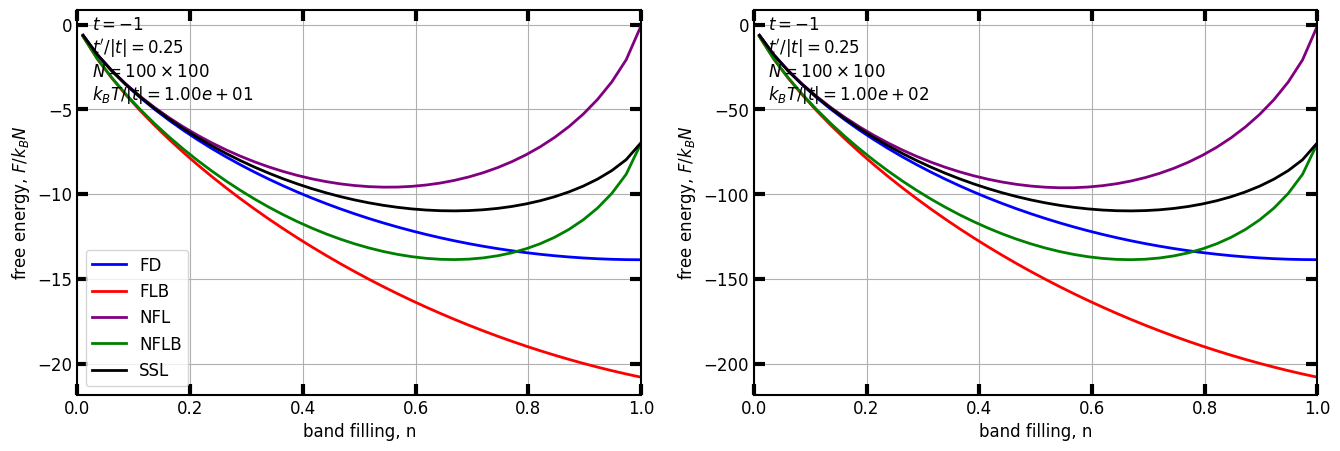

In [7]:
H_a_plot = H_a[0] 
beta_plot = 1/k_BT[-2:]

plotter.plot_scalar_result(
    results=energy_df,
    x_param="n",
    y_col="free_energy",
    y_label=r"free energy, $F / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="beta",
    subplots_vals=beta_plot,
    cols=2,
    figsize=(8, 5),
    t_prim=t_prim,
    N=N,
    xlims=(0, 1)
)
plt.show()